In [154]:
import pandas as pd
import geopandas as gpd
import numpy as np
import json
from shapely.geometry import shape
import seaborn as sns
import matplotlib.pyplot as plt
import folium

In [121]:
df_2020 = pd.read_csv(r'D:\Personal Projects\Assignment\Village_Economic_Growth_Intelligence\data\input_data\csvs\Goalpara_Village_Data_2020.csv')
df_2025 = pd.read_csv(r"D:\Personal Projects\Assignment\Village_Economic_Growth_Intelligence\data\input_data\csvs\Goalpara_Village_Data_2025.csv")


In [122]:
df_2020['geometry'] = df_2020['.geo'].apply(lambda x: shape(json.loads(x)) if pd.notnull(x) else None)
df_2025['geometry'] = df_2025['.geo'].apply(lambda x: shape(json.loads(x)) if pd.notnull(x) else None)

In [123]:
df_2020 = df_2020.drop(columns=['Unnamed: 0', 'system:index', '.geo'])
df_2025 = df_2025.drop(columns=['Unnamed: 0', 'system:index', '.geo'])

In [124]:
df_2025 = df_2025.drop(columns=['state_name',  'total_urba',
       'village', 'vlcode', 'geometry', 'shape_area', 'district',])

In [125]:
df_2025.columns

Index(['built', 'crops', 'nightlight_density', 'objectid_1',
       'total_population', 'trees'],
      dtype='str')

In [126]:
df_2025 = df_2025.rename(
    columns={
        col: f"{col}_2025"
        for col in df_2025.columns
        if col != "objectid_1"
    }
)

In [127]:
df_2020 = df_2020.rename(
    columns={
        col: f"{col}_2020"
        for col in df_2020.columns
        if col not in [ "objectid_1", 'district', 'shape_area', 'state_name', 'total_urba','village', 'vlcode', 'geometry']
    }
)

In [128]:
df_2020.columns

Index(['built_2020', 'crops_2020', 'district', 'nightlight_density_2020',
       'objectid_1', 'shape_area', 'state_name', 'total_population_2020',
       'total_urba', 'trees_2020', 'village', 'vlcode', 'geometry'],
      dtype='str')

In [129]:
df_merged = df_2020.merge(df_2025, how='inner', on='objectid_1')

--- Absolute Change Summary (2020 to 2025) ---
       built_change  crops_change  trees_change  nightlight_density_change  \
count      829.0000      829.0000      829.0000                   829.0000   
mean         0.0112       -0.0160        0.0289                     0.1189   
std          0.0159        0.0313        0.0263                     0.2481   
min         -0.0509       -0.1125       -0.0670                    -0.5224   
25%          0.0015       -0.0324        0.0108                     0.0283   
50%          0.0087       -0.0149        0.0294                     0.0953   
75%          0.0186       -0.0011        0.0473                     0.1706   
max          0.1015        0.1541        0.1334                     3.5130   

       total_population_change  
count                 829.0000  
mean                   48.3343  
std                    65.5093  
min                     0.0000  
25%                    11.0363  
50%                    29.6965  
75%                

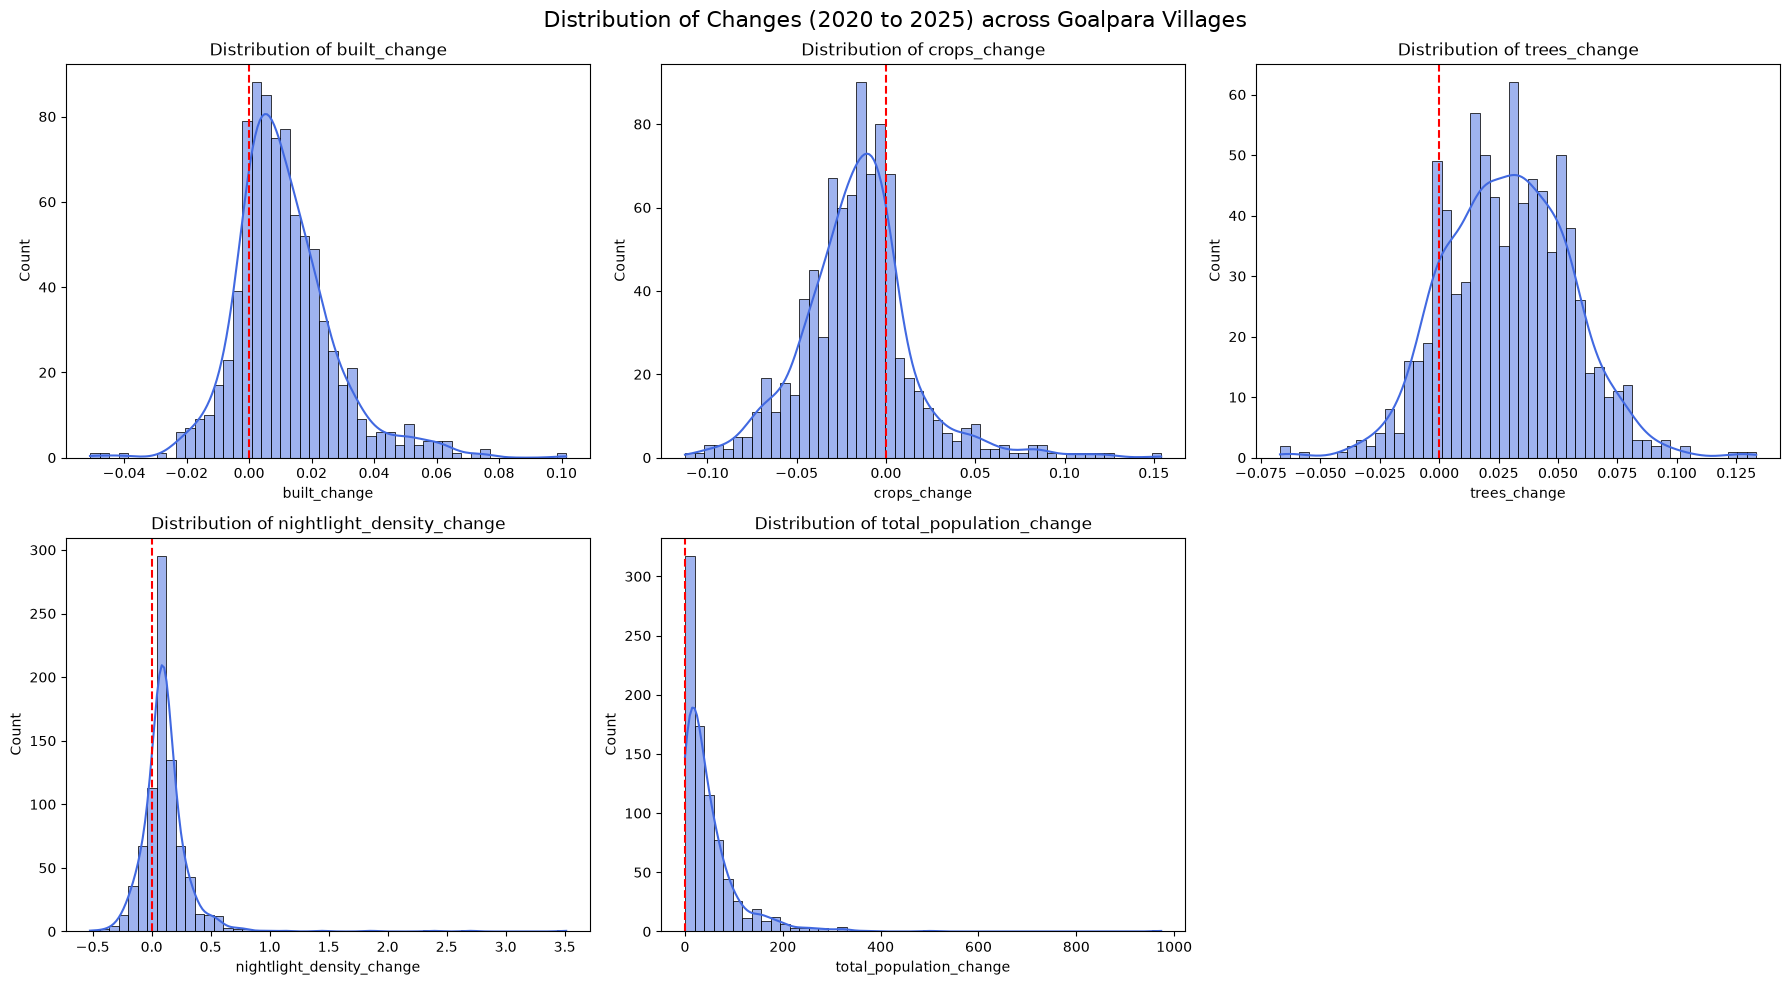

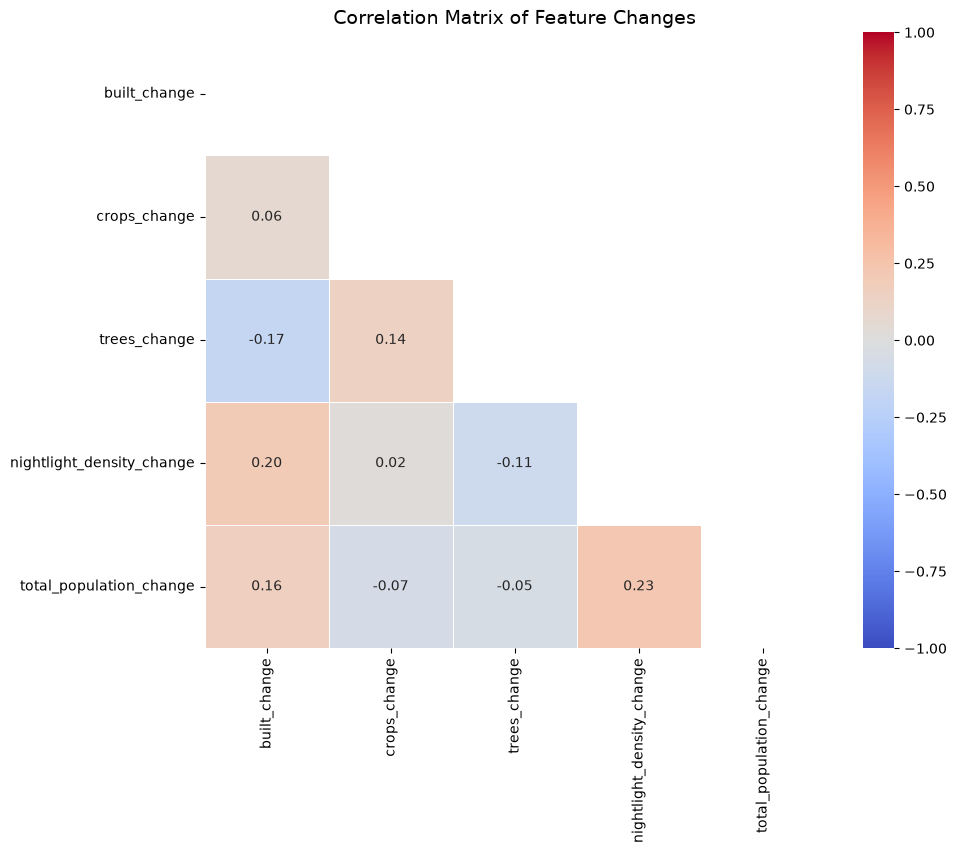

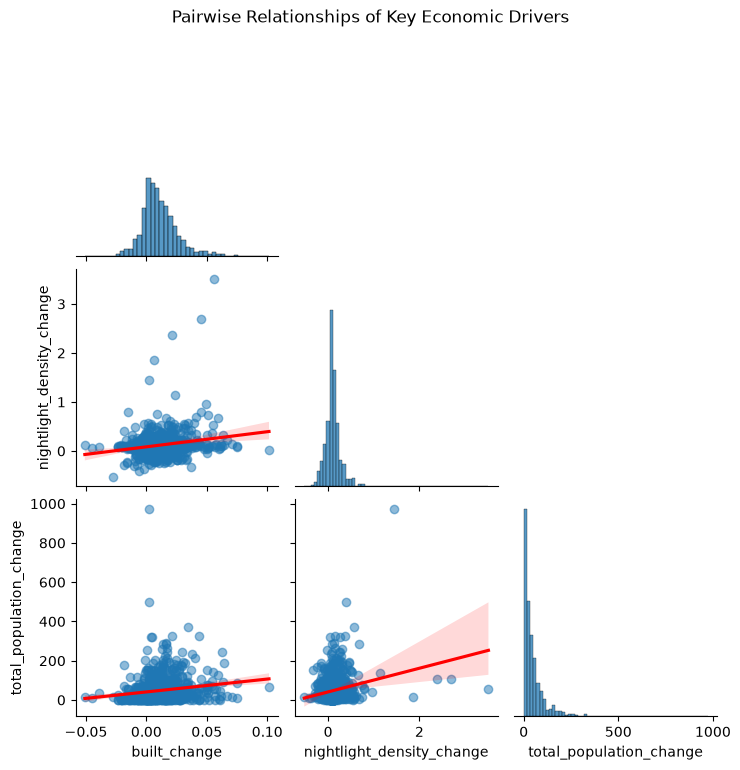

In [137]:
# 1. Calculate Absolute and Percentage Changes
features = ['built', 'crops', 'trees', 'nightlight_density', 'total_population']
change_cols = []
pct_cols = []

for f in features:
    # Absolute Change (2025 - 2020)
    abs_col = f'{f}_change'
    df_merged[abs_col] = df_merged[f'{f}_2025'] - df_merged[f'{f}_2020']
    change_cols.append(abs_col)
    
    # Percentage Change (using a small epsilon 1e-5 to prevent division by zero)
    pct_col = f'{f}_pct_change'
    df_merged[pct_col] = (df_merged[abs_col] / (df_merged[f'{f}_2020'] + 1e-5)) * 100
    pct_cols.append(pct_col)

# 2. Basic Statistical Summary (How much is it changing?)
print("--- Absolute Change Summary (2020 to 2025) ---")
print(df_merged[change_cols].describe().round(4))

# 3. Visualize the Distributions of Change
# We use subplots because features are on different scales (population vs. nightlights)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Distribution of Changes (2020 to 2025) across Goalpara Villages', fontsize=16)
axes = axes.flatten()

for i, col in enumerate(change_cols):
    sns.histplot(df_merged[col], kde=True, ax=axes[i], bins=50, color='royalblue')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].axvline(x=0, color='red', linestyle='--') # Add a zero line to see positive vs negative growth

# Remove the empty 6th subplot
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

# 4. Correlation Matrix (Which parameters move together?)
# We correlate the *changes*, not the raw 2020/2025 values, because we want to know 
# if an increase in built-up area correlates with an increase in nightlights/population.
plt.figure(figsize=(10, 8))
corr_matrix = df_merged[change_cols].corr()

# Mask the upper triangle for a cleaner look
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Feature Changes', fontsize=14)
plt.show()

# 5. Pairwise Scatter Plots for Top Economic Indicators
# Looking closely at Built-up vs Nightlights vs Population
economic_indicators = ['built_change', 'nightlight_density_change', 'total_population_change']
sns.pairplot(df_merged[economic_indicators], kind='reg', corner=True, 
             plot_kws={'line_kws':{'color':'red'}, 'scatter_kws': {'alpha': 0.5}})
plt.suptitle('Pairwise Relationships of Key Economic Drivers', y=1.02)
plt.show()

<Axes: ylabel='Density'>

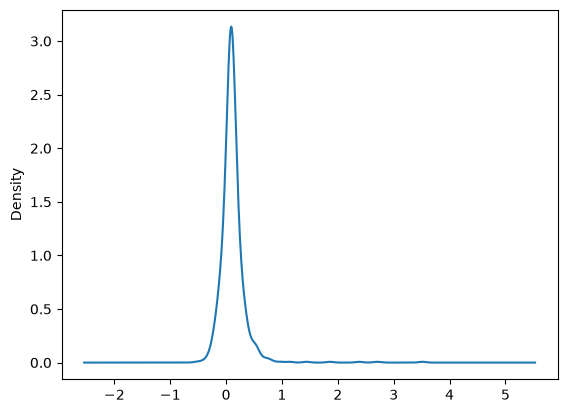

In [146]:
df_merged['nightlight_density_change'].plot(kind='kde')

In [148]:
df_merged = df_merged[df_merged['nightlight_density_change']<=1]

In [159]:
# 1. Ensure your merged dataframe is a GeoDataFrame
gdf_merged = gpd.GeoDataFrame(df_merged, geometry='geometry', crs="EPSG:4326")

# 2. Project to an Equal Area CRS (EPSG:6933) to accurately calculate area in square meters
gdf_merged_projected = gdf_merged.to_crs("EPSG:6933")

# 3. Calculate Area (converted from square meters to hectares for readability)
gdf_merged['area_hectares'] = gdf_merged_projected.geometry.area / 10000

# 4. Apply the Spatial Threshold
# 1 VIIRS pixel is ~21.4 hectares. 
# Filtering for > 50 hectares ensures the village covers at least ~2 full pixels.
spatial_threshold = 50 

# Filter out the small villages
gdf_valid_size = gdf_merged[gdf_merged['area_hectares'] >= spatial_threshold].copy()

print(f"Original villages: {len(gdf_merged)}")
print(f"Villages after spatial filtering: {len(gdf_valid_size)}")
print(f"Removed {len(gdf_merged) - len(gdf_valid_size)} villages due to VIIRS resolution constraints.")

Original villages: 823
Villages after spatial filtering: 739
Removed 84 villages due to VIIRS resolution constraints.


In [160]:
from sklearn.preprocessing import RobustScaler

# 1. Filter for Positive Growth
# We want villages that showed actual economic signals. 
# Filtering for villages where AT LEAST ONE primary economic proxy (lights or built-up) grew.
# This removes stagnant or declining villages from the ranking pool.
# growing_villages = df_merged[
#     (df_merged['built_change'] > 0) | 
#     (df_merged['nightlight_density_change'] > 0)
# ].copy()
growing_villages = df_merged[
    (df_merged['built_change'] > 0) & 
    (df_merged['nightlight_density_change'] > 0) & 
    (df_merged['total_population_change'] >= 0)
].copy()
# 2. Scale the Data (Using RobustScaler to handle the long-tail outliers)
scaler = RobustScaler()

features_to_scale = [
    'built_change', 
    'nightlight_density_change', 
    'total_population_change'
]
scaled_features = [f"{f}_scaled" for f in features_to_scale]

# Apply scaling
growing_villages[scaled_features] = scaler.fit_transform(growing_villages[features_to_scale])

# 3. Apply the Weighted Sum
w_built = 0.45
w_light = 0.45
w_pop = 0.10

# Calculate the composite Economic Growth Score
growing_villages['economic_growth_score'] = (
    (growing_villages['built_change_scaled'] * w_built) +
    (growing_villages['nightlight_density_change_scaled'] * w_light) +
    (growing_villages['total_population_change_scaled'] * w_pop)
)

# 4. Extract the Top 100 Villages
# This directly satisfies the core requirement of the assignment
top_100_villages = growing_villages.sort_values(by='economic_growth_score', ascending=False).head(100)

print("--- Top 100 Growing Villages Identified ---")
top_100_villages[['objectid_1', 'economic_growth_score','village'] + scaled_features].head(30)

--- Top 100 Growing Villages Identified ---


,objectid_1,economic_growth_score,village,built_change_scaled,nightlight_density_change_scaled,total_population_change_scaled
355,4098.0,3.990792,Lakheraj Mandalgram Pt I,2.326110,6.502322,0.179973
122,5590.0,3.406240,Dalgoma,2.920494,4.263149,1.736005
622,3783.0,3.350371,Gerapara,2.421157,4.852680,0.771439
811,4090.0,3.326539,Guabari Mandal Gram Hills,2.073653,5.206473,0.504824
119,5609.0,2.864561,Monakasa,2.701595,3.214844,2.021632
154,4097.0,2.799719,Khara Pt Ii,1.343840,3.528488,6.071717
673,3825.0,2.746944,Kulamuwa,1.793913,4.424772,-0.514643
535,5517.0,2.515228,Baladmari Char Pt Ii,0.190026,4.391530,4.535283
474,3803.0,2.295646,Gumaijhar,1.662061,3.488098,-0.219262
227,3788.0,2.284365,Chataimari,3.210795,1.629597,1.061886


In [161]:
# Convert the filtered pandas dataframe back to a GeoDataFrame
# Assuming 'geometry' was retained from df_2020 during your merge
top_100_gdf = gpd.GeoDataFrame(top_100_villages, geometry='geometry', crs="EPSG:4326")

# Recreate the full district GeoDataFrame for background context
# (Using your earlier df_2020 that already has the parsed geometry)
district_gdf = gpd.GeoDataFrame(df_2020, geometry='geometry', crs="EPSG:4326")

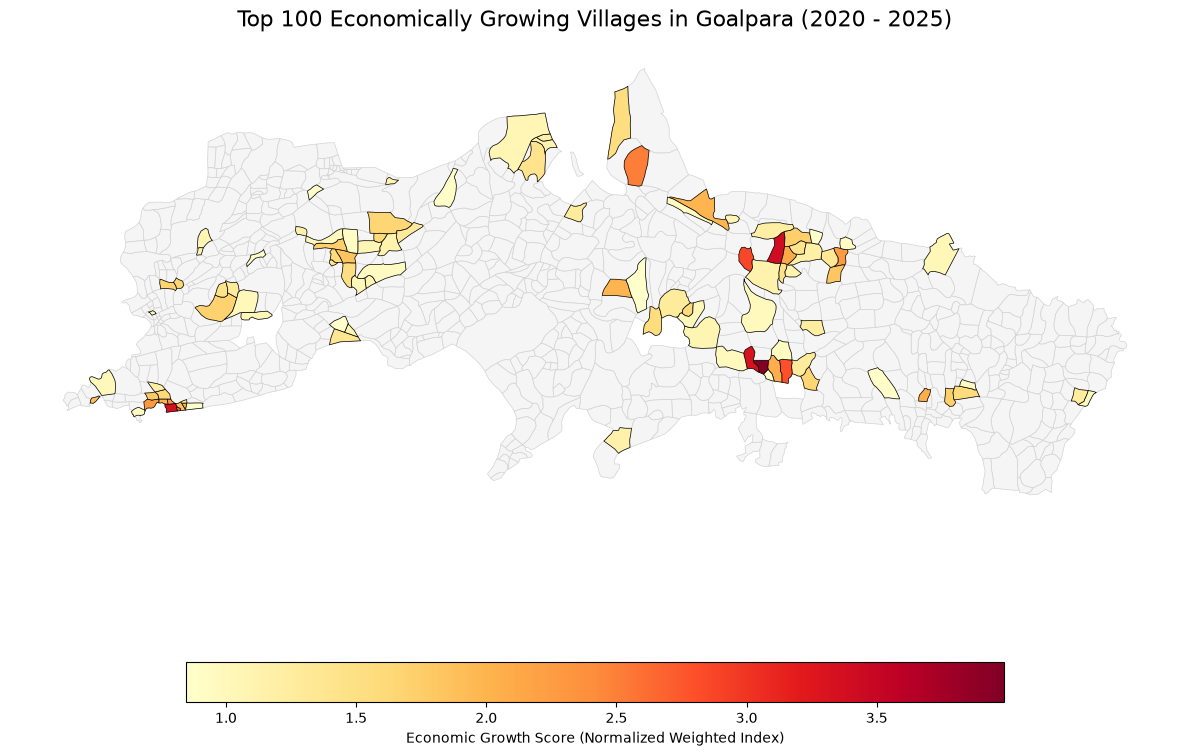

In [162]:
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

# Plot the entire district in light grey as a base map
district_gdf.plot(ax=ax, color='whitesmoke', edgecolor='lightgrey', linewidth=0.5)

# Overlay the top 100 growing villages, colored by their Economic Growth Score
plot = top_100_gdf.plot(
    column='economic_growth_score',
    ax=ax,
    cmap='YlOrRd', # Yellow to Red visually implies heat/growth
    legend=True,
    legend_kwds={
        'label': "Economic Growth Score (Normalized Weighted Index)",
        'orientation': "horizontal",
        'shrink': 0.7
    },
    edgecolor='black',
    linewidth=0.5
)

# Formatting for a non-technical audience
ax.set_title('Top 100 Economically Growing Villages in Goalpara (2020 - 2025)', fontsize=16, pad=15)
ax.set_axis_off() # Removes latitude/longitude axes for a cleaner look

plt.tight_layout()
plt.savefig('Goalpara_Economic_Growth_Map.png', dpi=300)
plt.show()

In [156]:
# Calculate the center of Goalpara for map initialization
center_lat = top_100_gdf.geometry.centroid.y.mean()
center_lon = top_100_gdf.geometry.centroid.x.mean()

# Initialize the interactive Folium map
m = folium.Map(location=[center_lat, center_lon], zoom_start=10, tiles='CartoDB positron')

# Create a choropleth layer
folium.Choropleth(
    geo_data=top_100_gdf.__geo_interface__,
    data=top_100_gdf,
    columns=['objectid_1', 'economic_growth_score'],
    key_on='feature.properties.objectid_1',
    fill_color='YlOrRd',
    fill_opacity=0.8,
    line_opacity=0.5,
    legend_name='Economic Growth Score (2020-2025)',
    highlight=True
).add_to(m)

# Add clickable tooltips to show village details on hover
folium.GeoJson(
    top_100_gdf,
    style_function=lambda x: {'fillColor': 'transparent', 'color': 'transparent'},
    tooltip=folium.GeoJsonTooltip(
        fields=['village', 'economic_growth_score', 'built_change', 'nightlight_density_change'],
        aliases=['Village Name:', 'Growth Score:', 'Built-up Change:', 'Nightlight Change:'],
        localize=True
    )
).add_to(m)

# Save the map to an HTML file
interactive_map_path = 'Top_100_Growing_Villages_Interactive.html'
m.save(interactive_map_path)
print(f"Interactive map saved to: {interactive_map_path}")

C:\Users\HP\AppData\Local\Temp\ipykernel_1044\1358199796.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  center_lat = top_100_gdf.geometry.centroid.y.mean()
C:\Users\HP\AppData\Local\Temp\ipykernel_1044\1358199796.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  center_lon = top_100_gdf.geometry.centroid.x.mean()
d:\Personal Projects\Assignment\Village_Economic_Growth_Intelligence\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Interactive map saved to: Top_100_Growing_Villages_Interactive.html
